<a href="https://colab.research.google.com/github/etoo-blip/Machine-Learning-Homework-1/blob/main/Homework_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# HOMEWORK 7: FULLY CONNECTED NEURAL NETWORKS FOR CIFAR-10
# Name: Edwin Too
# ID: 801549588
# Problem 1(a): Baseline Network

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

# Set random seed for reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Select GPU if available
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch version: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


In [3]:

# LOAD AND PREPROCESS CIFAR-10

# Normalize images using CIFAR-10 channel statistics
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.4914, 0.4822, 0.4465),
        std=(0.2470, 0.2435, 0.2616)
    )
])

# Download the official training and test datasets
train_dataset_full = datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Create a reproducible, stratified train/validation split
indices = np.arange(len(train_dataset_full))
labels = np.array(train_dataset_full.targets)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.10,
    random_state=SEED,
    stratify=labels
)

train_dataset = Subset(train_dataset_full, train_indices)
val_dataset = Subset(train_dataset_full, val_indices)

# Data loaders
BATCH_SIZE = 128

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

# CIFAR-10 class names
class_names = train_dataset_full.classes

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))
print("Classes:", class_names)

# Verify one batch
images, labels = next(iter(train_loader))

print("\nImage batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Flattened image size:", images[0].numel())


Training samples: 45000
Validation samples: 5000
Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

Image batch shape: torch.Size([128, 3, 32, 32])
Label batch shape: torch.Size([128])
Flattened image size: 3072


In [4]:

# BASELINE FULLY CONNECTED NEURAL NETWORK

class BaselineMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the model
baseline_model = BaselineMLP().to(device)

# Count trainable parameters
num_parameters = sum(
    p.numel()
    for p in baseline_model.parameters()
    if p.requires_grad
)

print(baseline_model)
print("\nTotal trainable parameters:", f"{num_parameters:,}")


BaselineMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,707,274


In [5]:

# TRAINING AND EVALUATION FUNCTIONS

import copy

def evaluate_model(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total += batch_size

    return total_loss / total, 100 * correct / total


def train_model(
    model,
    train_loader,
    val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_val_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    for epoch in range(epochs):
        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            batch_size = labels.size(0)

            running_loss += loss.item() * batch_size
            correct += (
                outputs.argmax(dim=1) == labels
            ).sum().item()
            total += batch_size

        train_loss = running_loss / total
        train_acc = 100 * correct / total

        val_loss, val_acc = evaluate_model(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Epoch {epoch+1:03d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2f}%"
        )

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if epochs_without_improvement >= patience:
            print(f"\nEarly stopping at epoch {epoch+1}")
            break

    if device.type == "cuda":
        torch.cuda.synchronize()

    training_time = time.perf_counter() - start_time

    # Restore the best model based on validation loss
    model.load_state_dict(best_weights)

    print(f"\nTraining time: {training_time:.2f} seconds")
    print(f"Epochs completed: {len(history['train_loss'])}")

    return history, training_time


In [6]:

# TRAIN BASELINE MODEL

baseline_history, baseline_time = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.6566 | Train Acc: 41.18% | Val Loss: 1.5362 | Val Acc: 45.20%
Epoch 002 | Train Loss: 1.4461 | Train Acc: 48.77% | Val Loss: 1.4604 | Val Acc: 48.92%
Epoch 003 | Train Loss: 1.3364 | Train Acc: 52.78% | Val Loss: 1.4081 | Val Acc: 51.02%
Epoch 004 | Train Loss: 1.2430 | Train Acc: 56.14% | Val Loss: 1.3820 | Val Acc: 51.46%
Epoch 005 | Train Loss: 1.1640 | Train Acc: 58.69% | Val Loss: 1.4075 | Val Acc: 51.54%
Epoch 006 | Train Loss: 1.0899 | Train Acc: 61.21% | Val Loss: 1.4105 | Val Acc: 51.54%
Epoch 007 | Train Loss: 1.0117 | Train Acc: 64.08% | Val Loss: 1.4395 | Val Acc: 52.16%
Epoch 008 | Train Loss: 0.9441 | Train Acc: 66.43% | Val Loss: 1.4502 | Val Acc: 52.04%
Epoch 009 | Train Loss: 0.8726 | Train Acc: 69.10% | Val Loss: 1.4748 | Val Acc: 52.88%
Epoch 010 | Train Loss: 0.8037 | Train Acc: 71.36% | Val Loss: 1.5610 | Val Acc: 53.10%
Epoch 011 | Train Loss: 0.7400 | Train Acc: 73.68% | Val Loss: 1.6359 | Val Acc: 53.40%
Epoch 012 | Train Loss: 0.6855 |

In [7]:

# FINAL BASELINE MODEL EVALUATION

criterion = nn.CrossEntropyLoss()

# The training function restored the best model weights
train_loss, train_acc = evaluate_model(
    baseline_model, train_loader, criterion
)

val_loss, val_acc = evaluate_model(
    baseline_model, val_loader, criterion
)

test_loss, test_acc = evaluate_model(
    baseline_model, test_loader, criterion
)

baseline_results = {
    "Model": "Baseline ReLU",
    "Hidden Layers": 2,
    "Parameters": num_parameters,
    "Epochs": len(baseline_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(baseline_history["val_loss"]) + 1
    ),
    "Training Time (s)": baseline_time,
    "Training Loss": train_loss,
    "Training Accuracy (%)": train_acc,
    "Validation Accuracy (%)": val_acc,
    "Test Accuracy (%)": test_acc
}

print("=" * 50)
print("PROBLEM 1(a): BASELINE FCNN RESULTS")
print("=" * 50)

for key, value in baseline_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("=" * 50)


PROBLEM 1(a): BASELINE FCNN RESULTS
Model: Baseline ReLU
Hidden Layers: 2
Parameters: 1707274
Epochs: 14
Best Epoch: 4
Training Time (s): 173.7967
Training Loss: 1.1147
Training Accuracy (%): 60.6911
Validation Accuracy (%): 51.4600
Test Accuracy (%): 51.5800


In [8]:

# PROBLEM 1(b) - FOUR HIDDEN LAYER MLP

class DeeperMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 512),
            nn.ReLU(),

            nn.Linear(512, 256),
            nn.ReLU(),

            nn.Linear(256, 256),
            nn.ReLU(),

            nn.Linear(256, 256),
            nn.ReLU(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the deeper model
deeper_model = DeeperMLP().to(device)

# Count trainable parameters
deeper_parameters = sum(
    p.numel()
    for p in deeper_model.parameters()
    if p.requires_grad
)

print(deeper_model)
print("\nTotal trainable parameters:",
      f"{deeper_parameters:,}")


DeeperMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,838,858


In [9]:

# TRAIN FOUR-HIDDEN-LAYER NETWORK

deeper_history, deeper_time = train_model(
    model=deeper_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.7029 | Train Acc: 39.02% | Val Loss: 1.5684 | Val Acc: 44.06%
Epoch 002 | Train Loss: 1.4756 | Train Acc: 47.88% | Val Loss: 1.4841 | Val Acc: 48.08%
Epoch 003 | Train Loss: 1.3580 | Train Acc: 52.01% | Val Loss: 1.3803 | Val Acc: 50.84%
Epoch 004 | Train Loss: 1.2583 | Train Acc: 55.32% | Val Loss: 1.3679 | Val Acc: 51.66%
Epoch 005 | Train Loss: 1.1744 | Train Acc: 58.42% | Val Loss: 1.3563 | Val Acc: 52.16%
Epoch 006 | Train Loss: 1.1002 | Train Acc: 60.74% | Val Loss: 1.3571 | Val Acc: 53.02%
Epoch 007 | Train Loss: 1.0245 | Train Acc: 63.44% | Val Loss: 1.3723 | Val Acc: 52.98%
Epoch 008 | Train Loss: 0.9534 | Train Acc: 65.83% | Val Loss: 1.4795 | Val Acc: 52.70%
Epoch 009 | Train Loss: 0.8833 | Train Acc: 68.32% | Val Loss: 1.4788 | Val Acc: 53.68%
Epoch 010 | Train Loss: 0.8121 | Train Acc: 70.56% | Val Loss: 1.4786 | Val Acc: 54.76%
Epoch 011 | Train Loss: 0.7559 | Train Acc: 72.62% | Val Loss: 1.5622 | Val Acc: 53.88%
Epoch 012 | Train Loss: 0.6966 |

In [10]:

# EVALUATE PROBLEM 1(b)

criterion = nn.CrossEntropyLoss()

deeper_train_loss, deeper_train_acc = evaluate_model(
    deeper_model, train_loader, criterion
)

deeper_val_loss, deeper_val_acc = evaluate_model(
    deeper_model, val_loader, criterion
)

deeper_test_loss, deeper_test_acc = evaluate_model(
    deeper_model, test_loader, criterion
)

deeper_results = {
    "Model": "Four-Layer ReLU",
    "Hidden Layers": 4,
    "Parameters": deeper_parameters,
    "Epochs": len(deeper_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(deeper_history["val_loss"]) + 1
    ),
    "Training Time (s)": deeper_time,
    "Training Loss": deeper_train_loss,
    "Training Accuracy (%)": deeper_train_acc,
    "Validation Accuracy (%)": deeper_val_acc,
    "Test Accuracy (%)": deeper_test_acc
}

print("=" * 50)
print("PROBLEM 1(b): DEEPER FCNN RESULTS")
print("=" * 50)

for key, value in deeper_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("=" * 50)


PROBLEM 1(b): DEEPER FCNN RESULTS
Model: Four-Layer ReLU
Hidden Layers: 4
Parameters: 1838858
Epochs: 15
Best Epoch: 5
Training Time (s): 187.6730
Training Loss: 1.0566
Training Accuracy (%): 62.3956
Validation Accuracy (%): 52.1600
Test Accuracy (%): 53.0700


In [11]:

# COMPARE BASELINE AND DEEPER NETWORKS

comparison_df = pd.DataFrame([
    baseline_results,
    deeper_results
])

display(comparison_df.round(3))


,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07


In [12]:

# PROBLEM 2(a) - TEN HIDDEN LAYER MLP

class DeepMLP(nn.Module):
    def __init__(self):
        super().__init__()

        layers = [
            nn.Flatten(),
            nn.Linear(3072, 512),
            nn.ReLU()
        ]

        # Add nine hidden layers with 256 neurons each
        layers.extend([
            nn.Linear(512, 256),
            nn.ReLU()
        ])

        for _ in range(8):
            layers.extend([
                nn.Linear(256, 256),
                nn.ReLU()
            ])

        # Output layer for 10 CIFAR-10 classes
        layers.append(nn.Linear(256, 10))

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


# Initialize model
deep_model = DeepMLP().to(device)

# Count trainable parameters
deep_parameters = sum(
    p.numel()
    for p in deep_model.parameters()
    if p.requires_grad
)

print(deep_model)
print("\nTotal trainable parameters:",
      f"{deep_parameters:,}")


DeepMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): ReLU()
    (5): Linear(in_features=256, out_features=256, bias=True)
    (6): ReLU()
    (7): Linear(in_features=256, out_features=256, bias=True)
    (8): ReLU()
    (9): Linear(in_features=256, out_features=256, bias=True)
    (10): ReLU()
    (11): Linear(in_features=256, out_features=256, bias=True)
    (12): ReLU()
    (13): Linear(in_features=256, out_features=256, bias=True)
    (14): ReLU()
    (15): Linear(in_features=256, out_features=256, bias=True)
    (16): ReLU()
    (17): Linear(in_features=256, out_features=256, bias=True)
    (18): ReLU()
    (19): Linear(in_features=256, out_features=256, bias=True)
    (20): ReLU()
    (21): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 2,233,610


In [13]:

# TRAIN TEN-HIDDEN-LAYER NETWORK

deep_history, deep_time = train_model(
    model=deep_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.9530 | Train Acc: 23.69% | Val Loss: 1.8030 | Val Acc: 30.18%
Epoch 002 | Train Loss: 1.7212 | Train Acc: 35.70% | Val Loss: 1.6567 | Val Acc: 38.92%
Epoch 003 | Train Loss: 1.5783 | Train Acc: 42.69% | Val Loss: 1.5960 | Val Acc: 42.80%
Epoch 004 | Train Loss: 1.4749 | Train Acc: 46.73% | Val Loss: 1.5001 | Val Acc: 46.48%
Epoch 005 | Train Loss: 1.3818 | Train Acc: 50.23% | Val Loss: 1.4622 | Val Acc: 48.50%
Epoch 006 | Train Loss: 1.2945 | Train Acc: 54.10% | Val Loss: 1.4284 | Val Acc: 50.46%
Epoch 007 | Train Loss: 1.2325 | Train Acc: 56.20% | Val Loss: 1.3984 | Val Acc: 51.58%
Epoch 008 | Train Loss: 1.1645 | Train Acc: 58.57% | Val Loss: 1.4405 | Val Acc: 51.48%
Epoch 009 | Train Loss: 1.1008 | Train Acc: 60.93% | Val Loss: 1.4255 | Val Acc: 51.86%
Epoch 010 | Train Loss: 1.0472 | Train Acc: 63.14% | Val Loss: 1.4959 | Val Acc: 50.26%
Epoch 011 | Train Loss: 0.9947 | Train Acc: 64.67% | Val Loss: 1.4395 | Val Acc: 51.96%
Epoch 012 | Train Loss: 0.9451 |

In [14]:

# EVALUATE PROBLEM 2(a)

criterion = nn.CrossEntropyLoss()

deep_train_loss, deep_train_acc = evaluate_model(
    deep_model, train_loader, criterion
)

deep_val_loss, deep_val_acc = evaluate_model(
    deep_model, val_loader, criterion
)

deep_test_loss, deep_test_acc = evaluate_model(
    deep_model, test_loader, criterion
)

deep_results = {
    "Model": "Ten-Layer ReLU",
    "Hidden Layers": 10,
    "Parameters": deep_parameters,
    "Epochs": len(deep_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(deep_history["val_loss"]) + 1
    ),
    "Training Time (s)": deep_time,
    "Training Loss": deep_train_loss,
    "Training Accuracy (%)": deep_train_acc,
    "Validation Accuracy (%)": deep_val_acc,
    "Test Accuracy (%)": deep_test_acc
}

print("=" * 50)
print("PROBLEM 2(a): TEN-LAYER FCNN RESULTS")
print("=" * 50)

for key, value in deep_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("=" * 50)

# Compare all three depth experiments
depth_comparison = pd.DataFrame([
    baseline_results,
    deeper_results,
    deep_results
])

display(depth_comparison.round(3))


PROBLEM 2(a): TEN-LAYER FCNN RESULTS
Model: Ten-Layer ReLU
Hidden Layers: 10
Parameters: 2233610
Epochs: 17
Best Epoch: 7
Training Time (s): 223.9461
Training Loss: 1.1157
Training Accuracy (%): 60.0511
Validation Accuracy (%): 51.5800
Test Accuracy (%): 51.1900


,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07
2,Ten-Layer ReLU,10,2233610,17,7,223.946,1.116,60.051,51.58,51.19


In [15]:

# PROBLEM 2(b) - EXPERIMENT 1
# INCREASING NETWORK WIDTH

class WiderMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 1024),
            nn.ReLU(),

            nn.Linear(1024, 512),
            nn.ReLU(),

            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the wider model
wider_model = WiderMLP().to(device)

# Count trainable parameters
wider_parameters = sum(
    p.numel()
    for p in wider_model.parameters()
    if p.requires_grad
)

print(wider_model)

print("\nTotal trainable parameters:",
      f"{wider_parameters:,}")


WiderMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): ReLU()
    (3): Linear(in_features=1024, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=10, bias=True)
  )
)

Total trainable parameters: 3,676,682


In [16]:

# TRAIN THE WIDER NETWORK

wider_history, wider_time = train_model(
    model=wider_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.6633 | Train Acc: 40.92% | Val Loss: 1.5208 | Val Acc: 46.74%
Epoch 002 | Train Loss: 1.4507 | Train Acc: 48.84% | Val Loss: 1.4635 | Val Acc: 48.20%
Epoch 003 | Train Loss: 1.3473 | Train Acc: 52.52% | Val Loss: 1.4364 | Val Acc: 50.04%
Epoch 004 | Train Loss: 1.2532 | Train Acc: 55.51% | Val Loss: 1.4339 | Val Acc: 50.14%
Epoch 005 | Train Loss: 1.1762 | Train Acc: 58.05% | Val Loss: 1.4338 | Val Acc: 50.78%
Epoch 006 | Train Loss: 1.0955 | Train Acc: 61.14% | Val Loss: 1.4482 | Val Acc: 51.82%
Epoch 007 | Train Loss: 1.0243 | Train Acc: 63.79% | Val Loss: 1.4662 | Val Acc: 52.26%
Epoch 008 | Train Loss: 0.9432 | Train Acc: 66.38% | Val Loss: 1.5366 | Val Acc: 51.58%
Epoch 009 | Train Loss: 0.8745 | Train Acc: 68.95% | Val Loss: 1.5324 | Val Acc: 53.20%
Epoch 010 | Train Loss: 0.8160 | Train Acc: 70.92% | Val Loss: 1.5892 | Val Acc: 52.90%
Epoch 011 | Train Loss: 0.7397 | Train Acc: 73.57% | Val Loss: 1.6236 | Val Acc: 52.66%
Epoch 012 | Train Loss: 0.6873 |

In [17]:

# EVALUATE THE WIDER NETWORK

criterion = nn.CrossEntropyLoss()

wider_train_loss, wider_train_acc = evaluate_model(
    wider_model, train_loader, criterion
)

wider_val_loss, wider_val_acc = evaluate_model(
    wider_model, val_loader, criterion
)

wider_test_loss, wider_test_acc = evaluate_model(
    wider_model, test_loader, criterion
)

wider_results = {
    "Model": "Wider ReLU",
    "Hidden Layers": 2,
    "Parameters": wider_parameters,
    "Epochs": len(wider_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(wider_history["val_loss"]) + 1
    ),
    "Training Time (s)": wider_time,
    "Training Loss": wider_train_loss,
    "Training Accuracy (%)": wider_train_acc,
    "Validation Accuracy (%)": wider_val_acc,
    "Test Accuracy (%)": wider_test_acc
}

print("=" * 50)
print("PROBLEM 2(b): WIDER NETWORK RESULTS")
print("=" * 50)

for key, value in wider_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

# Compare all completed experiments
comparison_df = pd.DataFrame([
    baseline_results,
    deeper_results,
    deep_results,
    wider_results
])

display(comparison_df.round(3))


PROBLEM 2(b): WIDER NETWORK RESULTS
Model: Wider ReLU
Hidden Layers: 2
Parameters: 3676682
Epochs: 15
Best Epoch: 5
Training Time (s): 185.1719
Training Loss: 1.0741
Training Accuracy (%): 61.6400
Validation Accuracy (%): 50.7800
Test Accuracy (%): 51.4900


,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07
2,Ten-Layer ReLU,10,2233610,17,7,223.946,1.116,60.051,51.58,51.19
3,Wider ReLU,2,3676682,15,5,185.172,1.074,61.640,50.78,51.49


In [18]:

# PROBLEM 2(b) - EXPERIMENT 2
# SIGMOID ACTIVATION NETWORK

class SigmoidMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 512),
            nn.Sigmoid(),

            nn.Linear(512, 256),
            nn.Sigmoid(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the Sigmoid model
sigmoid_model = SigmoidMLP().to(device)

# Count trainable parameters
sigmoid_parameters = sum(
    p.numel()
    for p in sigmoid_model.parameters()
    if p.requires_grad
)

print(sigmoid_model)
print("\nTotal trainable parameters:",
      f"{sigmoid_parameters:,}")


SigmoidMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): Sigmoid()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): Sigmoid()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,707,274


In [19]:

# TRAIN SIGMOID NETWORK

sigmoid_history, sigmoid_time = train_model(
    model=sigmoid_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.7839 | Train Acc: 36.76% | Val Loss: 1.6705 | Val Acc: 41.36%
Epoch 002 | Train Loss: 1.6058 | Train Acc: 43.66% | Val Loss: 1.5825 | Val Acc: 43.78%
Epoch 003 | Train Loss: 1.5156 | Train Acc: 46.68% | Val Loss: 1.5375 | Val Acc: 45.98%
Epoch 004 | Train Loss: 1.4480 | Train Acc: 48.85% | Val Loss: 1.5118 | Val Acc: 46.58%
Epoch 005 | Train Loss: 1.3890 | Train Acc: 51.01% | Val Loss: 1.4909 | Val Acc: 46.94%
Epoch 006 | Train Loss: 1.3349 | Train Acc: 53.00% | Val Loss: 1.4676 | Val Acc: 48.64%
Epoch 007 | Train Loss: 1.2834 | Train Acc: 54.74% | Val Loss: 1.4695 | Val Acc: 48.06%
Epoch 008 | Train Loss: 1.2379 | Train Acc: 56.16% | Val Loss: 1.4580 | Val Acc: 48.54%
Epoch 009 | Train Loss: 1.1831 | Train Acc: 58.45% | Val Loss: 1.4649 | Val Acc: 49.48%
Epoch 010 | Train Loss: 1.1425 | Train Acc: 59.66% | Val Loss: 1.4936 | Val Acc: 49.20%
Epoch 011 | Train Loss: 1.0983 | Train Acc: 61.36% | Val Loss: 1.4859 | Val Acc: 48.80%
Epoch 012 | Train Loss: 1.0574 |

In [20]:

# EVALUATE SIGMOID NETWORK
#

criterion = nn.CrossEntropyLoss()

sigmoid_train_loss, sigmoid_train_acc = evaluate_model(
    sigmoid_model, train_loader, criterion
)

sigmoid_val_loss, sigmoid_val_acc = evaluate_model(
    sigmoid_model, val_loader, criterion
)

sigmoid_test_loss, sigmoid_test_acc = evaluate_model(
    sigmoid_model, test_loader, criterion
)

sigmoid_results = {
    "Model": "Baseline Sigmoid",
    "Hidden Layers": 2,
    "Parameters": sigmoid_parameters,
    "Epochs": len(sigmoid_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(sigmoid_history["val_loss"]) + 1
    ),
    "Training Time (s)": sigmoid_time,
    "Training Loss": sigmoid_train_loss,
    "Training Accuracy (%)": sigmoid_train_acc,
    "Validation Accuracy (%)": sigmoid_val_acc,
    "Test Accuracy (%)": sigmoid_test_acc
}

print("=" * 50)
print("PROBLEM 2(b): SIGMOID NETWORK RESULTS")
print("=" * 50)

for key, value in sigmoid_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("=" * 50)

# Compare completed experiments
comparison_df = pd.DataFrame([
    baseline_results,
    deeper_results,
    deep_results,
    wider_results,
    sigmoid_results
])

display(comparison_df.round(3))


PROBLEM 2(b): SIGMOID NETWORK RESULTS
Model: Baseline Sigmoid
Hidden Layers: 2
Parameters: 1707274
Epochs: 18
Best Epoch: 8
Training Time (s): 223.4305
Training Loss: 1.1562
Training Accuracy (%): 59.4022
Validation Accuracy (%): 48.5400
Test Accuracy (%): 48.6000


,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07
2,Ten-Layer ReLU,10,2233610,17,7,223.946,1.116,60.051,51.58,51.19
3,Wider ReLU,2,3676682,15,5,185.172,1.074,61.640,50.78,51.49
4,Baseline Sigmoid,2,1707274,18,8,223.430,1.156,59.402,48.54,48.60


In [21]:

# PROBLEM 2(b) - EXPERIMENT 3
# TANH ACTIVATION NETWORK

class TanhMLP(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 512),
            nn.Tanh(),

            nn.Linear(512, 256),
            nn.Tanh(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)


# Initialize the Tanh model
tanh_model = TanhMLP().to(device)

# Count trainable parameters
tanh_parameters = sum(
    p.numel()
    for p in tanh_model.parameters()
    if p.requires_grad
)

print(tanh_model)
print("\nTotal trainable parameters:",
      f"{tanh_parameters:,}")


TanhMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=512, bias=True)
    (2): Tanh()
    (3): Linear(in_features=512, out_features=256, bias=True)
    (4): Tanh()
    (5): Linear(in_features=256, out_features=10, bias=True)
  )
)

Total trainable parameters: 1,707,274


In [22]:

# TRAIN TANH NETWORK

tanh_history, tanh_time = train_model(
    model=tanh_model,
    train_loader=train_loader,
    val_loader=val_loader,
    epochs=100,
    learning_rate=0.001,
    patience=10
)


Epoch 001 | Train Loss: 1.8069 | Train Acc: 36.84% | Val Loss: 1.6958 | Val Acc: 41.44%
Epoch 002 | Train Loss: 1.6694 | Train Acc: 42.17% | Val Loss: 1.6575 | Val Acc: 42.02%
Epoch 003 | Train Loss: 1.5979 | Train Acc: 44.67% | Val Loss: 1.6245 | Val Acc: 44.08%
Epoch 004 | Train Loss: 1.5510 | Train Acc: 46.32% | Val Loss: 1.6049 | Val Acc: 44.44%
Epoch 005 | Train Loss: 1.5027 | Train Acc: 47.78% | Val Loss: 1.5946 | Val Acc: 44.74%
Epoch 006 | Train Loss: 1.4529 | Train Acc: 49.81% | Val Loss: 1.5741 | Val Acc: 45.28%
Epoch 007 | Train Loss: 1.4165 | Train Acc: 50.90% | Val Loss: 1.5573 | Val Acc: 45.98%
Epoch 008 | Train Loss: 1.3848 | Train Acc: 51.89% | Val Loss: 1.5527 | Val Acc: 46.36%
Epoch 009 | Train Loss: 1.3522 | Train Acc: 53.20% | Val Loss: 1.5495 | Val Acc: 46.26%
Epoch 010 | Train Loss: 1.3224 | Train Acc: 54.12% | Val Loss: 1.5587 | Val Acc: 46.18%
Epoch 011 | Train Loss: 1.2934 | Train Acc: 54.81% | Val Loss: 1.5741 | Val Acc: 46.82%
Epoch 012 | Train Loss: 1.2567 |

In [23]:

# STEP 22: EVALUATE TANH NETWORK

criterion = nn.CrossEntropyLoss()

tanh_train_loss, tanh_train_acc = evaluate_model(
    tanh_model, train_loader, criterion
)

tanh_val_loss, tanh_val_acc = evaluate_model(
    tanh_model, val_loader, criterion
)

tanh_test_loss, tanh_test_acc = evaluate_model(
    tanh_model, test_loader, criterion
)

tanh_results = {
    "Model": "Baseline Tanh",
    "Hidden Layers": 2,
    "Parameters": tanh_parameters,
    "Epochs": len(tanh_history["train_loss"]),
    "Best Epoch": int(
        np.argmin(tanh_history["val_loss"]) + 1
    ),
    "Training Time (s)": tanh_time,
    "Training Loss": tanh_train_loss,
    "Training Accuracy (%)": tanh_train_acc,
    "Validation Accuracy (%)": tanh_val_acc,
    "Test Accuracy (%)": tanh_test_acc
}

print("=" * 50)
print("PROBLEM 2(b): TANH NETWORK RESULTS")
print("=" * 50)

for key, value in tanh_results.items():
    if isinstance(value, float):
        print(f"{key}: {value:.4f}")
    else:
        print(f"{key}: {value}")

print("=" * 50)

# Compare all six experiments
all_results = pd.DataFrame([
    baseline_results,
    deeper_results,
    deep_results,
    wider_results,
    sigmoid_results,
    tanh_results
])

display(all_results.round(3))


PROBLEM 2(b): TANH NETWORK RESULTS
Model: Baseline Tanh
Hidden Layers: 2
Parameters: 1707274
Epochs: 19
Best Epoch: 9
Training Time (s): 240.7592
Training Loss: 1.2655
Training Accuracy (%): 56.2333
Validation Accuracy (%): 46.2600
Test Accuracy (%): 46.6800


,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07
2,Ten-Layer ReLU,10,2233610,17,7,223.946,1.116,60.051,51.58,51.19
3,Wider ReLU,2,3676682,15,5,185.172,1.074,61.640,50.78,51.49
4,Baseline Sigmoid,2,1707274,18,8,223.430,1.156,59.402,48.54,48.60
5,Baseline Tanh,2,1707274,19,9,240.759,1.266,56.233,46.26,46.68


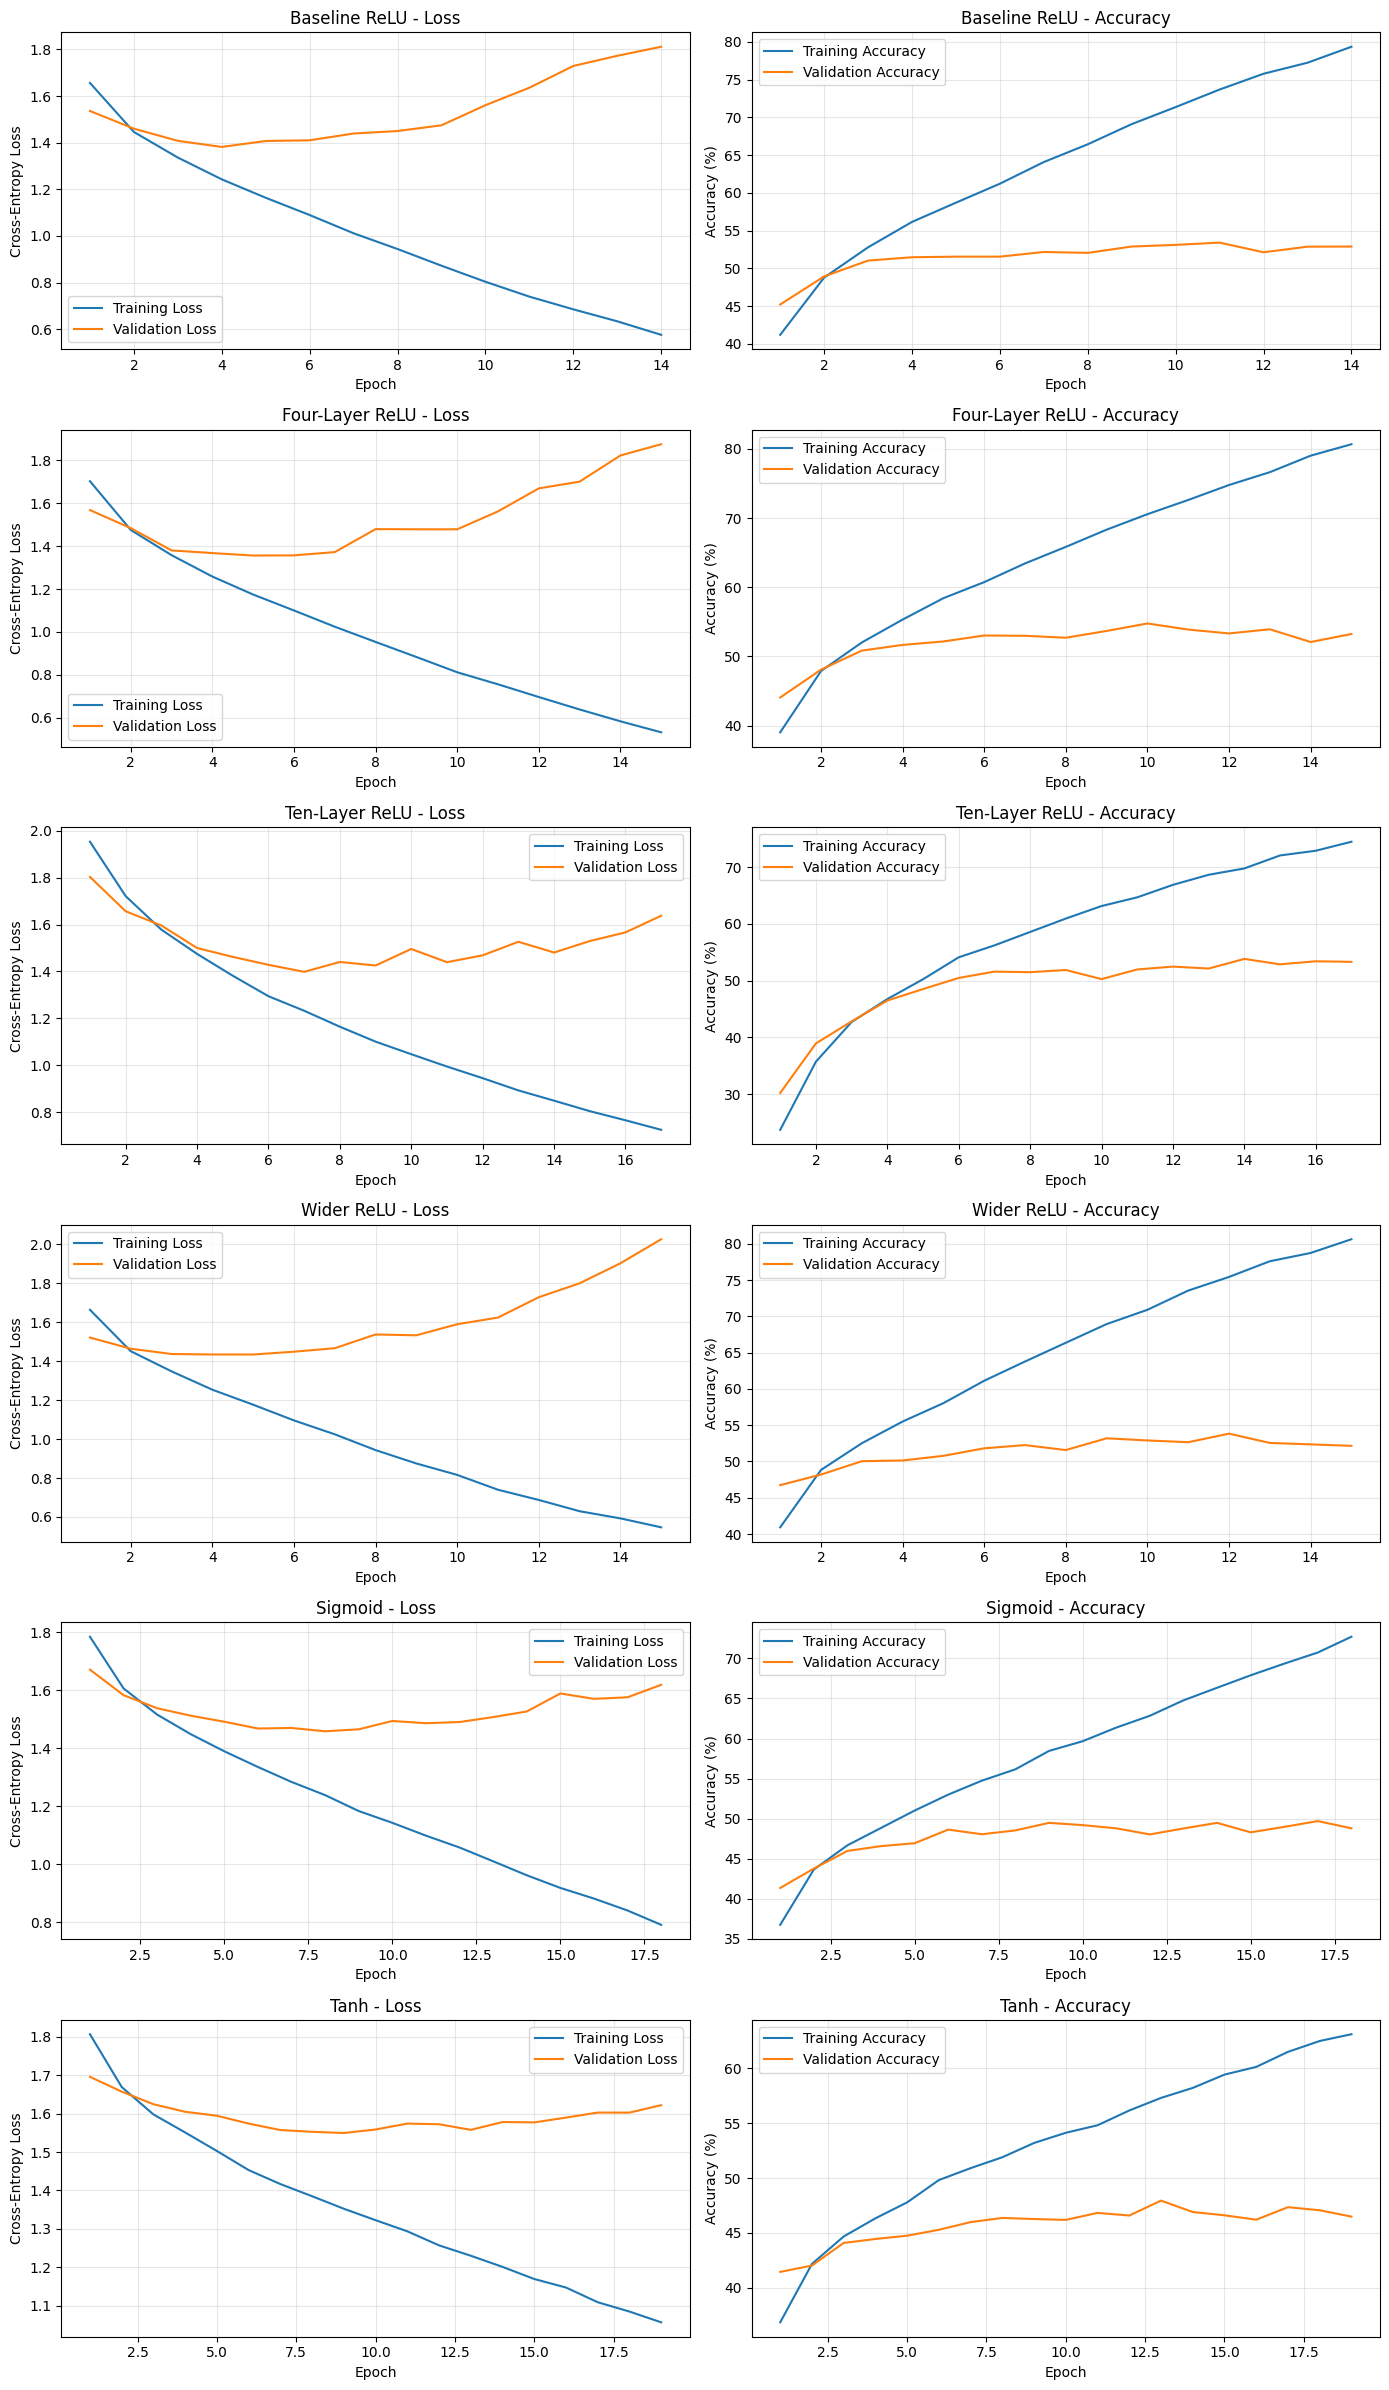

In [24]:

# TRAINING AND VALIDATION CURVES

histories = {
    "Baseline ReLU": baseline_history,
    "Four-Layer ReLU": deeper_history,
    "Ten-Layer ReLU": deep_history,
    "Wider ReLU": wider_history,
    "Sigmoid": sigmoid_history,
    "Tanh": tanh_history
}

fig, axes = plt.subplots(
    6, 2, figsize=(14, 24)
)

for row, (name, history) in enumerate(histories.items()):
    epochs = range(1, len(history["train_loss"]) + 1)

    # Loss curves
    axes[row, 0].plot(
        epochs, history["train_loss"],
        label="Training Loss"
    )
    axes[row, 0].plot(
        epochs, history["val_loss"],
        label="Validation Loss"
    )
    axes[row, 0].set_title(f"{name} - Loss")
    axes[row, 0].set_xlabel("Epoch")
    axes[row, 0].set_ylabel("Cross-Entropy Loss")
    axes[row, 0].legend()
    axes[row, 0].grid(alpha=0.3)

    # Accuracy curves
    axes[row, 1].plot(
        epochs, history["train_acc"],
        label="Training Accuracy"
    )
    axes[row, 1].plot(
        epochs, history["val_acc"],
        label="Validation Accuracy"
    )
    axes[row, 1].set_title(f"{name} - Accuracy")
    axes[row, 1].set_xlabel("Epoch")
    axes[row, 1].set_ylabel("Accuracy (%)")
    axes[row, 1].legend()
    axes[row, 1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Homework7_Training_Curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


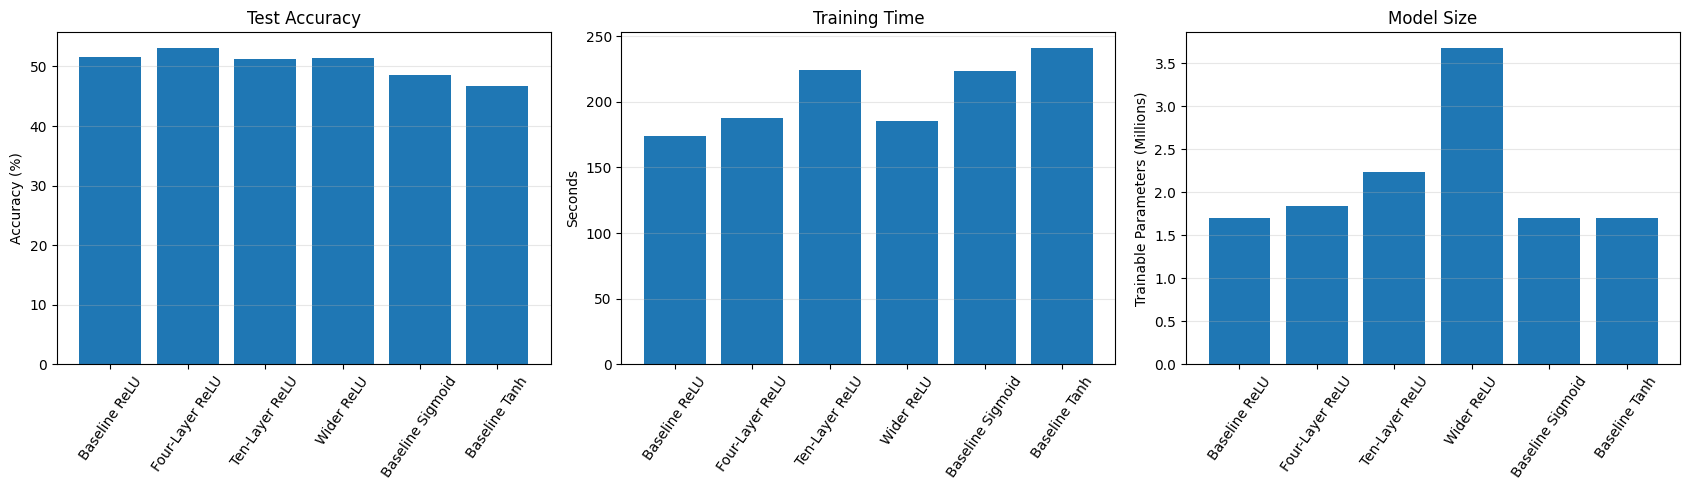

,Model,Hidden Layers,Parameters,Epochs,Best Epoch,Training Time (s),Training Loss,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%)
0,Baseline ReLU,2,1707274,14,4,173.797,1.115,60.691,51.46,51.58
1,Four-Layer ReLU,4,1838858,15,5,187.673,1.057,62.396,52.16,53.07
2,Ten-Layer ReLU,10,2233610,17,7,223.946,1.116,60.051,51.58,51.19
3,Wider ReLU,2,3676682,15,5,185.172,1.074,61.640,50.78,51.49
4,Baseline Sigmoid,2,1707274,18,8,223.430,1.156,59.402,48.54,48.60
5,Baseline Tanh,2,1707274,19,9,240.759,1.266,56.233,46.26,46.68


In [25]:

#FINAL MODEL COMPARISON

all_results = pd.DataFrame([
    baseline_results,
    deeper_results,
    deep_results,
    wider_results,
    sigmoid_results,
    tanh_results
])

# Save the complete comparison table
all_results.to_csv(
    "Homework7_Model_Results.csv",
    index=False
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

models = all_results["Model"]

axes[0].bar(
    models,
    all_results["Test Accuracy (%)"]
)
axes[0].set_title("Test Accuracy")
axes[0].set_ylabel("Accuracy (%)")

axes[1].bar(
    models,
    all_results["Training Time (s)"]
)
axes[1].set_title("Training Time")
axes[1].set_ylabel("Seconds")

axes[2].bar(
    models,
    all_results["Parameters"] / 1_000_000
)
axes[2].set_title("Model Size")
axes[2].set_ylabel("Trainable Parameters (Millions)")

for ax in axes:
    ax.tick_params(axis="x", rotation=55)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "Homework7_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

display(all_results.round(3))
